# 10 — XGBoost

> Hundreds of weak trees built one after another, each one correcting the mistakes of the last.

The summary of this lesson is in [README.md](README.md). This notebook is the
full working: the reasoning, the code, and the results.

**Contents**

1. The problem
2. Intuition
3. The mathematics
4. The data
5. Modeling
6. Results and interpretation
7. References

## 1. The problem

Predict the **median house value** of a California district from eight facts
about it: the median income of its residents, the age of its housing, its
rooms-per-household, its population, and where it sits on the map.

- **Inputs:** 8 numbers per district
- **Output:** median house value, in units of $100,000
- **A good answer** predicts districts the model has never seen, and the error is
  measured in dollars rather than in percentages correct.

Lesson 09 built a random forest: many deep trees, grown independently, averaged.
This lesson builds the other kind of ensemble, and the difference is not a
detail. It changes what the trees are for.

## 2. Intuition

A random forest is a **committee of experts voting at the same time**. Every tree
is grown independently on its own sample, every tree is strong on its own, and
nobody sees anyone else's answer. Averaging cancels out their individual quirks.

Boosting is a **relay team**. The first runner covers some ground badly. The
second does not start over — it looks at exactly where the first fell short and
works on that. The third corrects what the first two still get wrong. Each member
is weak on its own and is only asked to fix what remains.

Concretely, for predicting house prices:

1. Start by predicting the average price for every district. Terrible, but it is
   a start.
2. Look at the **residuals** — for each district, how far off that guess was.
3. Fit a small tree to **the residuals**, not to the prices. It learns "districts
   that look like this are underestimated by about $40,000".
4. Add a fraction of that correction to the running prediction.
5. Repeat, hundreds of times.

Each tree is shallow and nearly useless alone. The sum of hundreds of them is one
of the most accurate things available for tabular data.

| | Random forest (lesson 09) | Boosting (this lesson) |
|---|---|---|
| Trees built | in parallel, independently | in sequence, each depending on the last |
| Each tree is | deep and strong | shallow and deliberately weak |
| Each tree fits | the target | the **errors left over** |
| Mainly reduces | variance | bias |
| More trees | never hurt | **can** hurt |

## 3. The mathematics

**The model is a sum.** After $M$ rounds the prediction is

$$
\hat{y}(x) = F_0(x) + \eta \sum_{m=1}^{M} h_m(x)
$$

where $F_0$ is the starting guess (the mean), each $h_m$ is one small tree, and
$\eta$ is the **learning rate** — how much of each correction is actually
applied.

**Why residuals.** Take squared error as the cost:

$$
L = \frac{1}{2} \sum_i \left( y_i - \hat{y}_i \right)^2
$$

Differentiate with respect to the current prediction for one district:

$$
\frac{\partial L}{\partial \hat{y}_i} = \hat{y}_i - y_i = -(y_i - \hat{y}_i) = -\,\text{residual}_i
$$

The residual **is** the negative gradient. So fitting a tree to the residuals and
adding it is gradient descent — not in the space of parameters as in lesson 07,
but in the space of *functions*. That is why the method is called **gradient
boosting**: each tree is one downhill step, and $\eta$ is the step size.

This also explains how the method generalises. Swap in a different loss and the
"residual" becomes that loss's negative gradient instead; the rest of the
algorithm is unchanged, which is how the same machinery handles classification
and ranking.

**What XGBoost adds.** Plain gradient boosting uses the first derivative. XGBoost
expands the loss to second order, so each tree is chosen using both the slope
$g_i$ and the curvature $h_i$, and adds a penalty for complexity:

$$
\text{objective} = \sum_i \left( g_i f(x_i) + \tfrac{1}{2} h_i f(x_i)^2 \right) + \underbrace{\gamma T + \tfrac{1}{2}\lambda \sum_j w_j^2}_{\text{penalty on the tree}}
$$

$T$ is the number of leaves and $w_j$ their values, so $\gamma$ discourages big
trees and $\lambda$ discourages confident leaves — the same idea as Ridge in the
Tehran project, applied to trees.

**Why this one can overfit.** A forest's trees never see each other, so adding
more only refines an average. Boosting's trees are fitted to what is left over,
and eventually what is left over is noise. Keep going and the model starts
learning the noise. The defences are a small $\eta$, shallow trees, the penalties
above, and stopping early — all of which section 5 tries.

## 4. The data

California housing: 20,640 census block groups from the 1990 US census, each
summarised by eight numbers, with the median house value of the district as the
target.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")

# Fixed seed so the split, every tree and every number below are identical on
# each run.
RANDOM_SEED = 42

In [2]:
df = pd.read_csv("data/california_housing.csv")

print("shape:", df.shape)
print("missing values:", df.isnull().sum().sum())
df.head()

shape: (20640, 9)
missing values: 0


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
df.describe().round(2)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


Two things in that table deserve attention before any modelling.

**The target is capped.** `MedHouseVal` stops dead at 5.00, meaning $500,000.
Districts worth more than that were recorded as exactly 5.00 when the data was
collected.

**Some features have impossible maxima.** `AveRooms` reaches 141 and `AveOccup`
over 1200 — averages computed over block groups with very few households, such as
a hotel or a barracks.

districts sitting exactly at the $500k cap: 992  (4.8%)


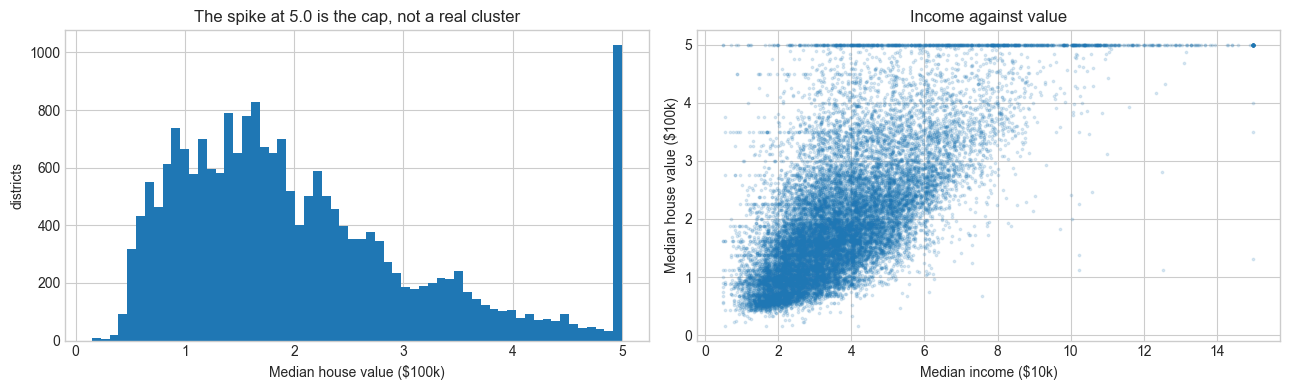

In [4]:
capped = (df["MedHouseVal"] >= 4.999).sum()
print(f"districts sitting exactly at the $500k cap: {capped}  ({capped / len(df):.1%})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df["MedHouseVal"], bins=60, color="tab:blue")
axes[0].set_xlabel("Median house value ($100k)")
axes[0].set_ylabel("districts")
axes[0].set_title("The spike at 5.0 is the cap, not a real cluster")

axes[1].scatter(df["MedInc"], df["MedHouseVal"], s=3, alpha=0.15, color="tab:blue")
axes[1].set_xlabel("Median income ($10k)")
axes[1].set_ylabel("Median house value ($100k)")
axes[1].set_title("Income against value")

plt.tight_layout()
plt.show()

The flat line of points along the top of the right-hand plot is that cap: 992
districts, 4.8% of the data, all recorded at exactly the same value regardless of
what they were really worth. No model can predict past a ceiling imposed by the
data collection, and section 6 comes back to what that does to the errors.

Income is clearly the strongest single predictor, but the spread around it is
wide — exactly the kind of structure where an ensemble earns its keep.

### Creating train and test datasets

In [5]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED
)

print("Train set:", X_train.shape)
print("Test set: ", X_test.shape)

# Predicting the training mean for everyone - the score any model must beat.
baseline_pred = np.full(len(y_test), y_train.mean())

Train set: (16512, 8)
Test set:  (4128, 8)


In [6]:
from sklearn.metrics import mean_absolute_error, r2_score

print(f"Baseline - always predict the mean: R2 {r2_score(y_test, baseline_pred):.4f}, "
      f"MAE ${mean_absolute_error(y_test, baseline_pred) * 100000:,.0f}")

Baseline - always predict the mean: R2 -0.0002, MAE $90,607


R² of roughly zero is what "no better than guessing the average" looks like, and
the typical miss is about $90,000. No scaling again: these are trees, and a
threshold does not care about units.

## 5. Modeling

### 5.1 One small tree, to show how weak a single step is

In [7]:
from sklearn.tree import DecisionTreeRegressor

stump = DecisionTreeRegressor(max_depth=3, random_state=RANDOM_SEED)
stump.fit(X_train, y_train)
stump_pred = stump.predict(X_test)

print(f"depth-3 tree:   R2 {r2_score(y_test, stump_pred):.4f}   MAE ${mean_absolute_error(y_test, stump_pred) * 100000:,.0f}")

deep = DecisionTreeRegressor(random_state=RANDOM_SEED).fit(X_train, y_train)
deep_pred = deep.predict(X_test)
print(f"unlimited tree: R2 {r2_score(y_test, deep_pred):.4f}   MAE ${mean_absolute_error(y_test, deep_pred) * 100000:,.0f}")

depth-3 tree:   R2 0.5098   MAE $59,783
unlimited tree: R2 0.6221   MAE $45,468


A depth-3 tree can ask only three questions before committing to an answer, so it
explains about half the variation. This is the "weak learner" boosting is built
from — and the thing to watch is that hundreds of these will beat the unlimited
tree, and beat lesson 09's forest of unlimited trees too.

### 5.2 The concept: boosting by hand

The whole algorithm from section 2, in eight lines:

1. start with the mean
2. compute the residuals — what is still wrong
3. fit a depth-3 tree **to the residuals**
4. add a fraction $\eta$ of its prediction
5. repeat

In [8]:
learning_rate = 0.1
n_rounds = 200

# 1. the starting guess: the training mean, for everyone
train_pred = np.full(len(y_train), y_train.mean())
test_pred = np.full(len(y_test), y_train.mean())

history = []
for round_i in range(1, n_rounds + 1):
    # 2. what is still wrong - and this is exactly the negative gradient of
    #    squared error, from section 3
    residuals = y_train - train_pred

    # 3. a small tree fitted to the mistakes, not to the prices
    corrector = DecisionTreeRegressor(max_depth=3, random_state=RANDOM_SEED)
    corrector.fit(X_train, residuals)

    # 4. take a small step in that direction
    train_pred = train_pred + learning_rate * corrector.predict(X_train)
    test_pred = test_pred + learning_rate * corrector.predict(X_test)

    history.append({"round": round_i, "test R2": r2_score(y_test, test_pred)})

for r in [1, 2, 5, 10, 25, 50, 100, 200]:
    print(f"  {r:3d} trees: test R2 {history[r - 1]['test R2']:.4f}")

    1 trees: test R2 0.0981
    2 trees: test R2 0.1788
    5 trees: test R2 0.3534
   10 trees: test R2 0.5014
   25 trees: test R2 0.6671
   50 trees: test R2 0.7435
  100 trees: test R2 0.7757
  200 trees: test R2 0.8006


Compare that first line with lesson 09. There, the very first tree in the forest
already scored 0.895 — it was a complete model on its own. Here the first tree
scores **0.098**, barely better than guessing the mean, because it was never
asked to predict a price. It was asked to predict a correction.

By 200 rounds the sum of those corrections passes the unlimited single tree and
closes on the random forest. Nothing in that loop is more complicated than
"subtract, fit, add".

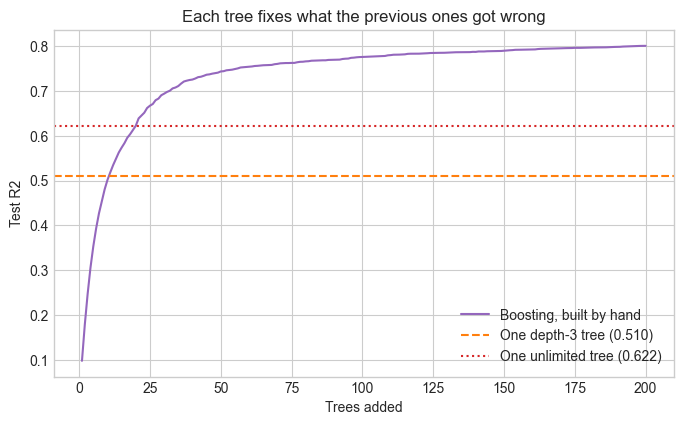

In [9]:
hist = pd.DataFrame(history).set_index("round")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(hist.index, hist["test R2"], color="tab:purple", label="Boosting, built by hand")
ax.axhline(r2_score(y_test, stump_pred), color="tab:orange", linestyle="--",
           label=f"One depth-3 tree ({r2_score(y_test, stump_pred):.3f})")
ax.axhline(r2_score(y_test, deep_pred), color="tab:red", linestyle=":",
           label=f"One unlimited tree ({r2_score(y_test, deep_pred):.3f})")
ax.set_xlabel("Trees added")
ax.set_ylabel("Test R2")
ax.set_title("Each tree fixes what the previous ones got wrong")
ax.legend()
plt.show()

### 5.3 The same thing, from XGBoost

`XGBRegressor` runs the same loop, with the second-order objective and the
penalties from section 3, written in C++ and parallelised.

In [10]:
import time

import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor

t0 = time.time()
model = xgb.XGBRegressor(n_estimators=100, random_state=RANDOM_SEED, n_jobs=-1)
model.fit(X_train, y_train)
xgb_time = time.time() - t0
xgb_pred = model.predict(X_test)

t0 = time.time()
forest = RandomForestRegressor(n_estimators=100, random_state=RANDOM_SEED, n_jobs=-1)
forest.fit(X_train, y_train)
forest_time = time.time() - t0
forest_pred = forest.predict(X_test)

print(f"hand-built boosting (200): R2 {history[-1]['test R2']:.4f}")
print(f"XGBoost (100):             R2 {r2_score(y_test, xgb_pred):.4f}   fitted in {xgb_time:.2f}s")
print(f"Random forest (100):       R2 {r2_score(y_test, forest_pred):.4f}   fitted in {forest_time:.2f}s")

hand-built boosting (200): R2 0.8006
XGBoost (100):             R2 0.8301   fitted in 0.20s
Random forest (100):       R2 0.8051   fitted in 2.44s


XGBoost beats the hand-built version with half the trees, beats lesson 09's
forest, and fits in a fraction of the time. The speed gap is worth dwelling on:
the forest grows 100 trees to full depth, while XGBoost grows 100 trees of depth
6 using histogram-based splitting — far less work per tree.

### 5.4 The learning rate

$\eta$ decides how much of each correction is applied. Too small and the model
never arrives within the number of trees allowed; too large and each step
overshoots.

In [11]:
rows = []
for eta in [0.01, 0.05, 0.1, 0.3, 1.0]:
    m = xgb.XGBRegressor(n_estimators=300, learning_rate=eta, max_depth=6,
                         random_state=RANDOM_SEED, n_jobs=-1).fit(X_train, y_train)
    rows.append({"learning rate": eta, "test R2": r2_score(y_test, m.predict(X_test))})

lr_results = pd.DataFrame(rows).set_index("learning rate")
print(lr_results.round(4).to_string())

               test R2
learning rate         
0.01            0.7705
0.05            0.8336
0.10            0.8409
0.30            0.8309
1.00            0.7258


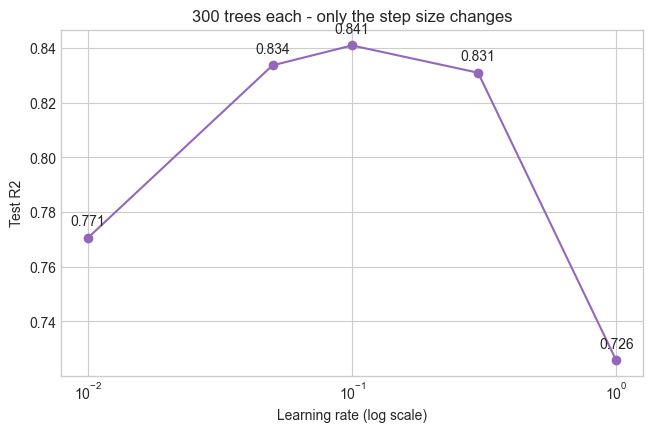

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(lr_results.index, lr_results["test R2"], marker="o", color="tab:purple")
ax.set_xscale("log")
ax.set_xlabel("Learning rate (log scale)")
ax.set_ylabel("Test R2")
ax.set_title("300 trees each - only the step size changes")
for eta, r2 in lr_results["test R2"].items():
    ax.annotate(f"{r2:.3f}", (eta, r2), textcoords="offset points", xytext=(0, 9), ha="center")
plt.savefig("figures/learning_rate.png", dpi=150, bbox_inches="tight")
plt.show()

A clear peak around 0.1, and real damage at both ends. At 0.01 the model has not
finished arriving after 300 trees; at 1.0 each tree overcorrects and the trees
start fighting one another.

This is the first setting in this repository where the rule is not simply "more
is better" — $\eta$ and `n_estimators` trade against each other. Halving the
learning rate roughly doubles the number of trees needed.

### 5.5 When more trees start to hurt

Lesson 09 found that adding trees to a forest never hurts. Boosting is different,
and the risk depends on how much data there is to learn from. With 16,512
training districts there is enough signal that extra trees simply stop helping.
Cut the training set to 500 districts and the difference shows.

In [13]:
X_small, y_small = X_train.iloc[:500], y_train.iloc[:500]

rows = []
for n in [10, 50, 100, 300, 600, 1200]:
    m = xgb.XGBRegressor(n_estimators=n, learning_rate=0.05, max_depth=3,
                         reg_lambda=1, random_state=RANDOM_SEED, n_jobs=-1).fit(X_small, y_small)
    rows.append({
        "trees": n,
        "train R2": r2_score(y_small, m.predict(X_small)),
        "test R2": r2_score(y_test, m.predict(X_test)),
    })

small_results = pd.DataFrame(rows).set_index("trees")
print("500 training districts, gentle settings (lr 0.05, depth 3, reg_lambda 1)")
print(small_results.round(4).to_string())

500 training districts, gentle settings (lr 0.05, depth 3, reg_lambda 1)
       train R2  test R2
trees                   
10       0.3939   0.3400
50       0.7638   0.6201
100      0.8460   0.6642
300      0.9318   0.6887
600      0.9714   0.6884
1200     0.9944   0.6836


In [14]:
rows = []
for n in [10, 50, 100, 300, 600, 1200]:
    m = xgb.XGBRegressor(n_estimators=n, learning_rate=0.3, max_depth=8,
                         reg_lambda=0, random_state=RANDOM_SEED, n_jobs=-1).fit(X_small, y_small)
    rows.append({
        "trees": n,
        "train R2": r2_score(y_small, m.predict(X_small)),
        "test R2": r2_score(y_test, m.predict(X_test)),
    })

aggressive = pd.DataFrame(rows).set_index("trees")
print("same 500 districts, aggressive settings (lr 0.3, depth 8, no penalty)")
print(aggressive.round(4).to_string())

same 500 districts, aggressive settings (lr 0.3, depth 8, no penalty)
       train R2  test R2
trees                   
10       0.9951   0.5823
50       1.0000   0.5875
100      1.0000   0.5875
300      1.0000   0.5875
600      1.0000   0.5875
1200     1.0000   0.5875


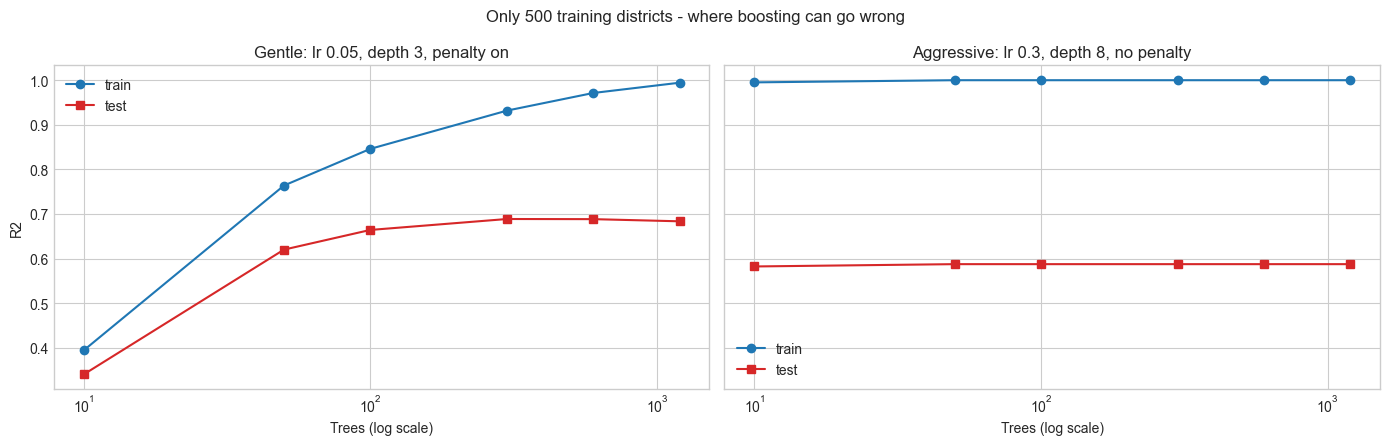

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)

for ax, data, title in [
    (axes[0], small_results, "Gentle: lr 0.05, depth 3, penalty on"),
    (axes[1], aggressive, "Aggressive: lr 0.3, depth 8, no penalty"),
]:
    ax.plot(data.index, data["train R2"], marker="o", label="train", color="tab:blue")
    ax.plot(data.index, data["test R2"], marker="s", label="test", color="tab:red")
    ax.set_xscale("log")
    ax.set_xlabel("Trees (log scale)")
    ax.set_title(title)
    ax.legend()

axes[0].set_ylabel("R2")
fig.suptitle("Only 500 training districts - where boosting can go wrong")
plt.tight_layout()
plt.savefig("figures/overfitting.png", dpi=150, bbox_inches="tight")
plt.show()

Two things to read here.

**On the left**, test R² rises to a peak around 300 trees and then drifts *down*
while train R² keeps climbing toward 1.0. That downturn is the thing a random
forest cannot do. Past the peak, the extra trees are fitting noise.

**On the right**, aggressive settings memorise all 500 districts within about ten
trees — train R² is already 1.0 — and test R² is stuck roughly ten points below
what the gentle settings eventually reach. Adding trees after that changes
nothing, because there is no error left to fit; the damage was done in the first
few rounds.

That comparison is the entire argument for a small learning rate, shallow trees
and the penalty terms. They do not slow the model down for the sake of it: they
stop it spending its capacity on noise.

### 5.6 Letting the model choose when to stop

If there is a peak, the number of trees should not be guessed. Hold out a slice
of the **training** data, watch the error on it after every tree, and stop when it
stops improving.

In [16]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=RANDOM_SEED
)

early = xgb.XGBRegressor(
    n_estimators=3000,
    learning_rate=0.05,
    max_depth=6,
    early_stopping_rounds=50,
    random_state=RANDOM_SEED,
    n_jobs=-1,
)
early.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], verbose=False)

early_pred = early.predict(X_test)
print(f"allowed up to 3000 trees, stopped at {early.best_iteration}")
print(f"test R2: {r2_score(y_test, early_pred):.4f}   MAE ${mean_absolute_error(y_test, early_pred) * 100000:,.0f}")

allowed up to 3000 trees, stopped at 937
test R2: 0.8456   MAE $29,345


The validation slice comes out of the training data, never the test set — the
same discipline as choosing K in lesson 05 and C in lesson 07. The test set is
still untouched at this point.

## 6. Results and interpretation

In [17]:
def summarise(name, pred):
    return {
        "Model": name,
        "Test R2": r2_score(y_test, pred),
        "MAE ($)": mean_absolute_error(y_test, pred) * 100000,
    }

summary = pd.DataFrame([
    summarise("Always predict the mean", baseline_pred),
    summarise("Single tree, depth 3", stump_pred),
    summarise("Single tree, unlimited", deep_pred),
    summarise("Boosting by hand (200)", test_pred),
    summarise("Random forest (100)", forest_pred),
    summarise("XGBoost, defaults (100)", xgb_pred),
    summarise("XGBoost, early stopping", early_pred),
]).set_index("Model")

summary.round({"Test R2": 4, "MAE ($)": 0})

,Test R2,MAE ($)
Model,,
Always predict the mean,-0.0002,90607.0
"Single tree, depth 3",0.5098,59783.0
"Single tree, unlimited",0.6221,45468.0
Boosting by hand (200),0.8006,34826.0
Random forest (100),0.8051,32754.0
"XGBoost, defaults (100)",0.8301,30957.0
"XGBoost, early stopping",0.8456,29345.0


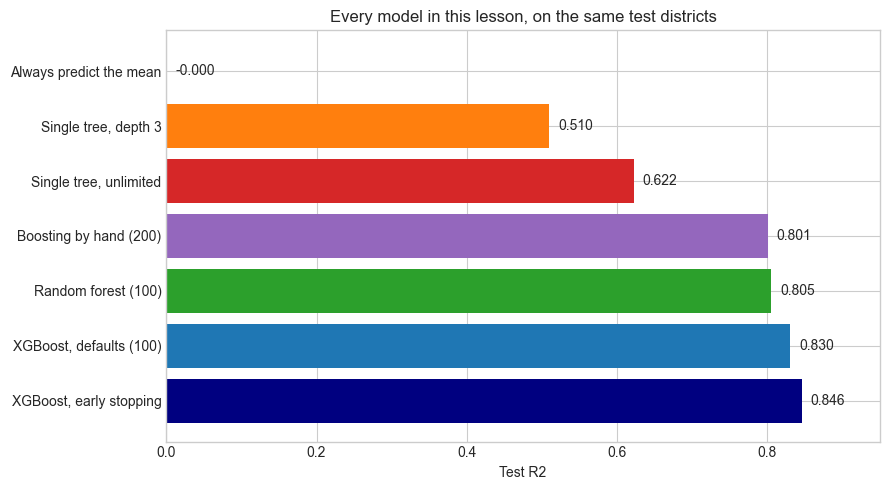

In [18]:
fig, ax = plt.subplots(figsize=(9, 5))
colours = ["grey", "tab:orange", "tab:red", "tab:purple", "tab:green", "tab:blue", "navy"]
bars = ax.barh(summary.index[::-1], summary["Test R2"][::-1], color=colours[::-1])
ax.set_xlabel("Test R2")
ax.set_xlim(0, 0.95)
ax.set_title("Every model in this lesson, on the same test districts")
for bar, v in zip(bars, summary["Test R2"][::-1]):
    ax.text(v + 0.012, bar.get_y() + bar.get_height() / 2, f"{v:.3f}", va="center")

plt.tight_layout()
# Saved so README.md can show the result without anyone running this notebook.
plt.savefig("figures/result.png", dpi=150, bbox_inches="tight")
plt.show()

### Which features matter

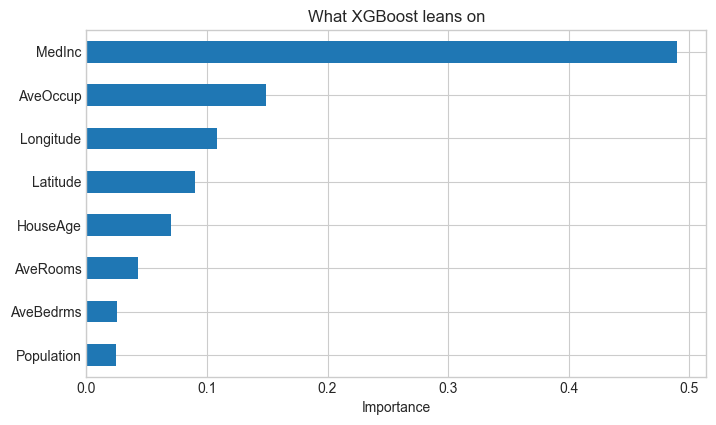

MedInc        0.4896
AveOccup      0.1486
Longitude     0.1080
Latitude      0.0903
HouseAge      0.0701
AveRooms      0.0431
AveBedrms     0.0257
Population    0.0247


In [19]:
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
importances.iloc[::-1].plot.barh(ax=ax, color="tab:blue")
ax.set_xlabel("Importance")
ax.set_title("What XGBoost leans on")
plt.savefig("figures/importances.png", dpi=150, bbox_inches="tight")
plt.show()

print(importances.round(4).to_string())

Median income dominates, which is unsurprising. The interesting entries are
**latitude and longitude**: between them they carry a large share of the
importance, because the trees use them to carve California into regions — coastal
against inland, Bay Area against Central Valley. A linear model would have to be
told about neighbourhoods explicitly, as the Tehran project was. The trees
discover the map by repeatedly splitting on coordinates.

The same caution as lesson 09 applies: importance records what the model *used*,
not what *causes* house prices, and correlated features share the credit.

### Where it fails

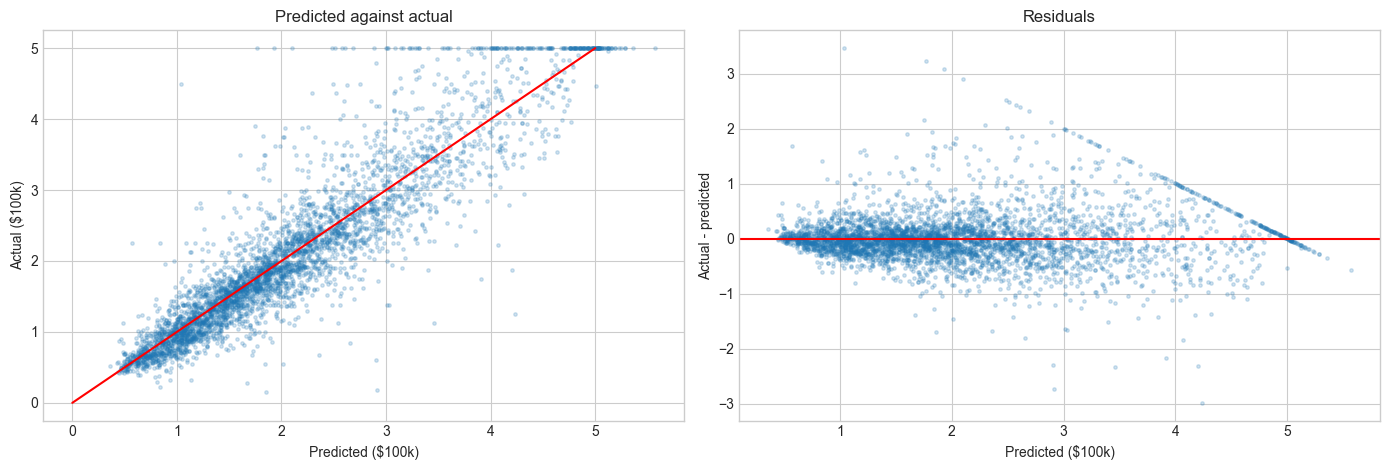

test districts at the $500k cap: 184
  mean error there:           $62,251
  mean error everywhere else: $27,810


In [20]:
residuals_test = y_test - early_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

axes[0].scatter(early_pred, y_test, s=6, alpha=0.2, color="tab:blue")
axes[0].plot([0, 5], [0, 5], color="red", linewidth=1.5)
axes[0].set_xlabel("Predicted ($100k)")
axes[0].set_ylabel("Actual ($100k)")
axes[0].set_title("Predicted against actual")

axes[1].scatter(early_pred, residuals_test, s=6, alpha=0.2, color="tab:blue")
axes[1].axhline(0, color="red", linewidth=1.5)
axes[1].set_xlabel("Predicted ($100k)")
axes[1].set_ylabel("Actual - predicted")
axes[1].set_title("Residuals")

plt.tight_layout()
plt.show()

at_cap = y_test >= 4.999
print(f"test districts at the $500k cap: {at_cap.sum()}")
print(f"  mean error there:           ${mean_absolute_error(y_test[at_cap], early_pred[at_cap]) * 100000:,.0f}")
print(f"  mean error everywhere else: ${mean_absolute_error(y_test[~at_cap], early_pred[~at_cap]) * 100000:,.0f}")

The horizontal stripe along the top of the left-hand plot is the $500,000 cap.
Those districts all carry the same recorded value and genuinely different real
values, so the model is punished for predicting anything other than exactly 5.0 —
and its error on them is several times its error everywhere else.

That is not a modelling failure. It is a measurement limit baked into the data in
1990, and no algorithm can see past it. The honest options are to exclude the
capped districts, or to report their error separately, as above.

### Reading the result

Boosting beats bagging on this dataset, and the margin is real but not enormous —
a few points of R², a few thousand dollars of typical error. The much larger gap
is between any ensemble and a single tree.

**What was gained over lesson 09:**

- Better accuracy, from correcting errors instead of averaging them away.
- Much faster fitting, because the trees are shallow.
- A model that keeps improving as it is tuned, where a forest is close to its
  ceiling out of the box.

**What it cost:**

- **Settings that matter.** A forest works at its defaults; here the learning
  rate, depth and tree count interact, and bad choices lose ten points.
- **A real way to go wrong.** More trees can make a boosted model worse, which is
  impossible for a forest.
- **An extra dependency.** XGBoost is not part of scikit-learn.

**When to reach for which.** A random forest is the better first thing to try:
almost impossible to misconfigure, and it tells you quickly whether the features
carry signal at all. Boosting is what to reach for when that signal exists and
the last few points matter — which is why gradient boosting wins most tabular
competitions and random forests remain the sensible default.

Neither changes the ceiling set by the data. Both models are stopped by the same
$500,000 cap.

## 7. References

- Dataset: California housing, derived from the 1990 US census, distributed with
  scikit-learn as `sklearn.datasets.fetch_california_housing`. Originally from
  Pace, R. K. and Barry, R. (1997), *Sparse Spatial Autoregressions*.
- Chen, T. and Guestrin, C. (2016). *XGBoost: A Scalable Tree Boosting System* -
  the paper describing the second-order objective and penalties in section 3.
- Friedman, J. (2001). *Greedy Function Approximation: A Gradient Boosting
  Machine* - where boosting is framed as gradient descent in function space.
- [XGBoost documentation](https://xgboost.readthedocs.io/en/stable/)
- Builds directly on [lesson 09 - Random Forest](../09-random-forest/), the other
  way of combining trees.